<ipython-input-3-e4e8bb4c5335>:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Age'].fillna(dataset['Age'].median(), inplace=True)
<ipython-input-3-e4e8bb4c5335>:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True

Neural Network Accuracy:  0.5222222222222223
Decision Tree Accuracy:  0.4777777777777778
Logistic Regression Accuracy:  0.5133333333333333

Neural Network Classification Report: 
               precision    recall  f1-score   support

           0       0.53      0.58      0.55       229
           1       0.52      0.46      0.49       221

    accuracy                           0.52       450
   macro avg       0.52      0.52      0.52       450
weighted avg       0.52      0.52      0.52       450


Decision Tree Classification Report: 
               precision    recall  f1-score   support

           0       0.49      0.45      0.47       229
           1       0.47      0.50      0.49       221

    accuracy                           0.48       450
   macro avg       0.48      0.48      0.48       450
weighted avg       0.48      0.48      0.48       450


Logistic Regression Classification Report: 
               precision    recall  f1-score   support

           0       0.52  

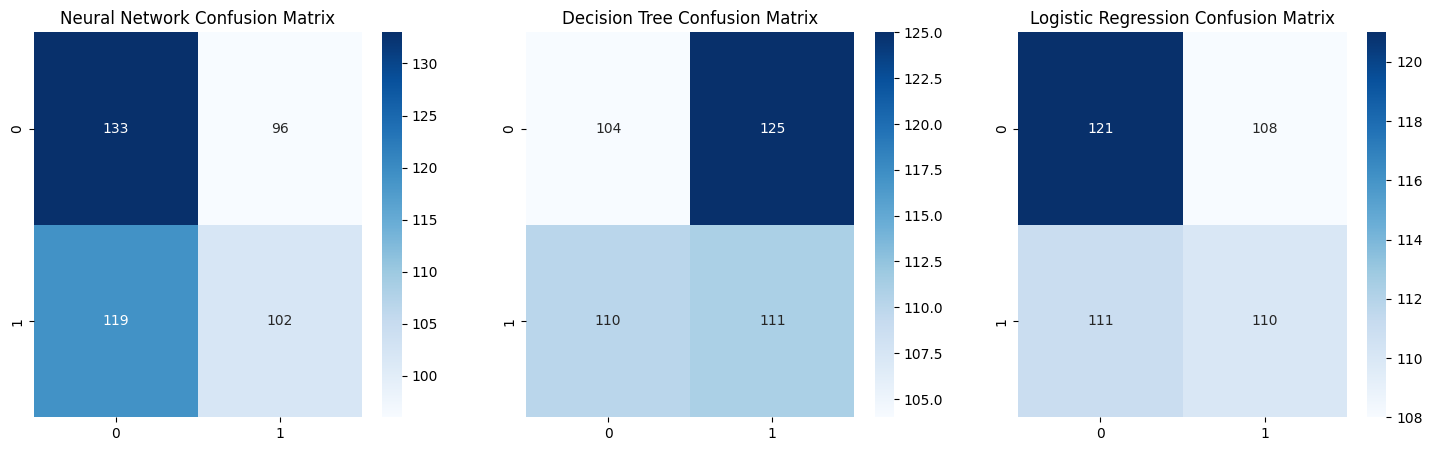

In [3]:
# Import necessary libraries
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
dataset_path = '/content/consumer_classification_dataset.csv'
dataset = pd.read_csv(dataset_path)

# Handle missing values
dataset['Age'].fillna(dataset['Age'].median(), inplace=True)
dataset['Income'].fillna(dataset['Income'].median(), inplace=True)
dataset['Credit_Score'].fillna(dataset['Credit_Score'].median(), inplace=True)
dataset['Gender'].fillna(dataset['Gender'].mode()[0], inplace=True)

# Encode categorical variables
label_encoder = LabelEncoder()
dataset['Gender'] = label_encoder.fit_transform(dataset['Gender'])
dataset['Marital_Status'] = label_encoder.fit_transform(dataset['Marital_Status'])
dataset['Device_Used'] = label_encoder.fit_transform(dataset['Device_Used'])

# Split the dataset into features (X) and target (y)
X = dataset.drop('Churn', axis=1)
y = dataset['Churn']

# Split into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize models
neural_net = MLPClassifier(random_state=42)
decision_tree = DecisionTreeClassifier(random_state=42)
logistic_reg = LogisticRegression(random_state=42)

# Train the models
neural_net.fit(X_train, y_train)
decision_tree.fit(X_train, y_train)
logistic_reg.fit(X_train, y_train)

# Predict on the test set
y_pred_nn = neural_net.predict(X_test)
y_pred_dt = decision_tree.predict(X_test)
y_pred_lr = logistic_reg.predict(X_test)

# Evaluate the models
accuracy_nn = accuracy_score(y_test, y_pred_nn)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
accuracy_lr = accuracy_score(y_test, y_pred_lr)

# Classification reports
report_nn = classification_report(y_test, y_pred_nn)
report_dt = classification_report(y_test, y_pred_dt)
report_lr = classification_report(y_test, y_pred_lr)

# Confusion Matrices
conf_matrix_nn = confusion_matrix(y_test, y_pred_nn)
conf_matrix_dt = confusion_matrix(y_test, y_pred_dt)
conf_matrix_lr = confusion_matrix(y_test, y_pred_lr)

# R² and MSE for comparison (only for regression problems)
r2_nn = r2_score(y_test, y_pred_nn)
r2_dt = r2_score(y_test, y_pred_dt)
r2_lr = r2_score(y_test, y_pred_lr)

mse_nn = mean_squared_error(y_test, y_pred_nn)
mse_dt = mean_squared_error(y_test, y_pred_dt)
mse_lr = mean_squared_error(y_test, y_pred_lr)

# Display the results
print("Neural Network Accuracy: ", accuracy_nn)
print("Decision Tree Accuracy: ", accuracy_dt)
print("Logistic Regression Accuracy: ", accuracy_lr)

print("\nNeural Network Classification Report: \n", report_nn)
print("\nDecision Tree Classification Report: \n", report_dt)
print("\nLogistic Regression Classification Report: \n", report_lr)

# Display R² and MSE for each model
print("\nR² Scores:")
print(f"Neural Network: {r2_nn}")
print(f"Decision Tree: {r2_dt}")
print(f"Logistic Regression: {r2_lr}")

print("\nMean Squared Errors:")
print(f"Neural Network: {mse_nn}")
print(f"Decision Tree: {mse_dt}")
print(f"Logistic Regression: {mse_lr}")

# Confusion matrices visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(conf_matrix_nn, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title('Neural Network Confusion Matrix')

sns.heatmap(conf_matrix_dt, annot=True, fmt="d", cmap="Blues", ax=axes[1])
axes[1].set_title('Decision Tree Confusion Matrix')

sns.heatmap(conf_matrix_lr, annot=True, fmt="d", cmap="Blues", ax=axes[2])
axes[2].set_title('Logistic Regression Confusion Matrix')

plt.show()
